# Results summary: final model, parameter count and test accuracy

Team **Bonnie & Clyde** (Aditya Jha, Pragya Awasthi). This notebook

1. builds the final WRN-22 student and the teacher networks from the model code in `train.py` and prints their trainable parameter counts,
2. prints the final test accuracy of our two selected Kaggle submissions, and
3. plots validation and test accuracy for every model we submitted.

It runs on CPU in a few seconds; no data download is needed. The training runs themselves (with their logs and outputs) are in the other notebooks in this folder.

In [1]:
import ast, pathlib
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

# Load only the model definitions from train.py (the rest of the script is the training entry point).
src = pathlib.Path('../train.py').read_text() if pathlib.Path('../train.py').exists() else pathlib.Path('train.py').read_text()
tree = ast.parse(src)
keep = [n for n in tree.body if isinstance(n, (ast.ClassDef, ast.FunctionDef)) and n.name not in ('spec_from_args', 'load_teacher', 'log', 'predict', 'train_step', 'soft_targets', 'mix_batch', 'zs')]
ns = {'torch': torch, 'nn': nn, 'F': F, 'math': __import__('math'), 'Dataset': torch.utils.data.Dataset}
exec(compile(ast.Module(body=keep, type_ignores=[]), 'train.py', 'exec'), ns)
build = ns['build']

def n_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

## 1. Final model and parameter count

In [2]:
final_spec = dict(arch='wrn', depth=22, widths=[72, 144, 264], dropout=0.0, se=False)
model = build(final_spec)
count = n_params(model)
print(model.__class__.__name__, final_spec)
print(f'Trainable parameters of the final model: {count:,}')
print(f'Under the 5,000,000 limit: {count <= 5_000_000}')
with torch.no_grad():
    out = model.eval()(torch.randn(2, 3, 32, 32))
print('Output shape for a batch of 2 CIFAR-10 images:', tuple(out.shape))

PreActWRN {'arch': 'wrn', 'depth': 22, 'widths': [72, 144, 264], 'dropout': 0.0, 'se': False}
Trainable parameters of the final model: 4,806,954
Under the 5,000,000 limit: True
Output shape for a batch of 2 CIFAR-10 images: (2, 10)


In [3]:
rows = [('WRN-22 72/144/264 (final student)', final_spec),
        ('PyramidNet-164 alpha 100 (student)', dict(arch='pyramid', depth=164, alpha=100, pL=0.5)),
        ('WRN-28-10 (teacher)', dict(arch='wrn', depth=28, widths=[160, 320, 640], dropout=0.3, se=False)),
        ('Shake-Shake 26 2x96d (teacher)', dict(arch='shake', depth=26, w=96)),
        ('PyramidNet-272 alpha 200 (teacher)', dict(arch='pyramid', depth=272, alpha=200, pL=0.5))]
for name, spec in rows:
    c = n_params(build(spec))
    print(f'{name:42s} {c:>12,}  {"under 5M" if c <= 5_000_000 else "over 5M: teacher only, never submitted"}')

WRN-22 72/144/264 (final student)             4,806,954  under 5M
PyramidNet-164 alpha 100 (student)            4,924,834  under 5M


WRN-28-10 (teacher)                          36,479,194  over 5M: teacher only, never submitted


Shake-Shake 26 2x96d (teacher)               26,192,922  over 5M: teacher only, never submitted


PyramidNet-272 alpha 200 (teacher)           26,210,842  over 5M: teacher only, never submitted


## 2. Final test accuracy

The test labels are hidden, so test accuracy comes from the Kaggle leaderboard (2,000 held out images: 1,000 public, 1,000 private). Validation is our own 5,000 image split of the training data, with test time augmentation.

In [4]:
final = [
    # name, teachers, train images, validation, public test, private test
    ('kd1p_sam_600',    'PyramidNet-272',                              45000, 0.9790, 0.897, 0.872),
    ('kd5_sam_full600', '3x WRN-28-10 + Shake-Shake + PyramidNet-272', 50000, 0.9812, 0.897, 0.870),
]
for name, teachers, n, val, pub, priv in final:
    print(f'{name}: {count:,} params | teachers: {teachers} | trained on {n:,} images')
    note = ' (run trained on the 45k split)' if n == 50000 else ''
    print(f'    validation {val:.2%}{note} | public test {pub:.1%} | private test {priv:.1%}')
best = max(final, key=lambda r: r[5])
print(f'\nFINAL TEST ACCURACY (Kaggle private leaderboard): {best[5]:.1%}  ({best[0]}, {count:,} parameters, rank 34 of 81)')

kd1p_sam_600: 4,806,954 params | teachers: PyramidNet-272 | trained on 45,000 images
    validation 97.90% | public test 89.7% | private test 87.2%
kd5_sam_full600: 4,806,954 params | teachers: 3x WRN-28-10 + Shake-Shake + PyramidNet-272 | trained on 50,000 images
    validation 98.12% (run trained on the 45k split) | public test 89.7% | private test 87.0%

FINAL TEST ACCURACY (Kaggle private leaderboard): 87.2%  (kd1p_sam_600, 4,806,954 parameters, rank 34 of 81)


## 3. Every submitted model: validation vs test accuracy

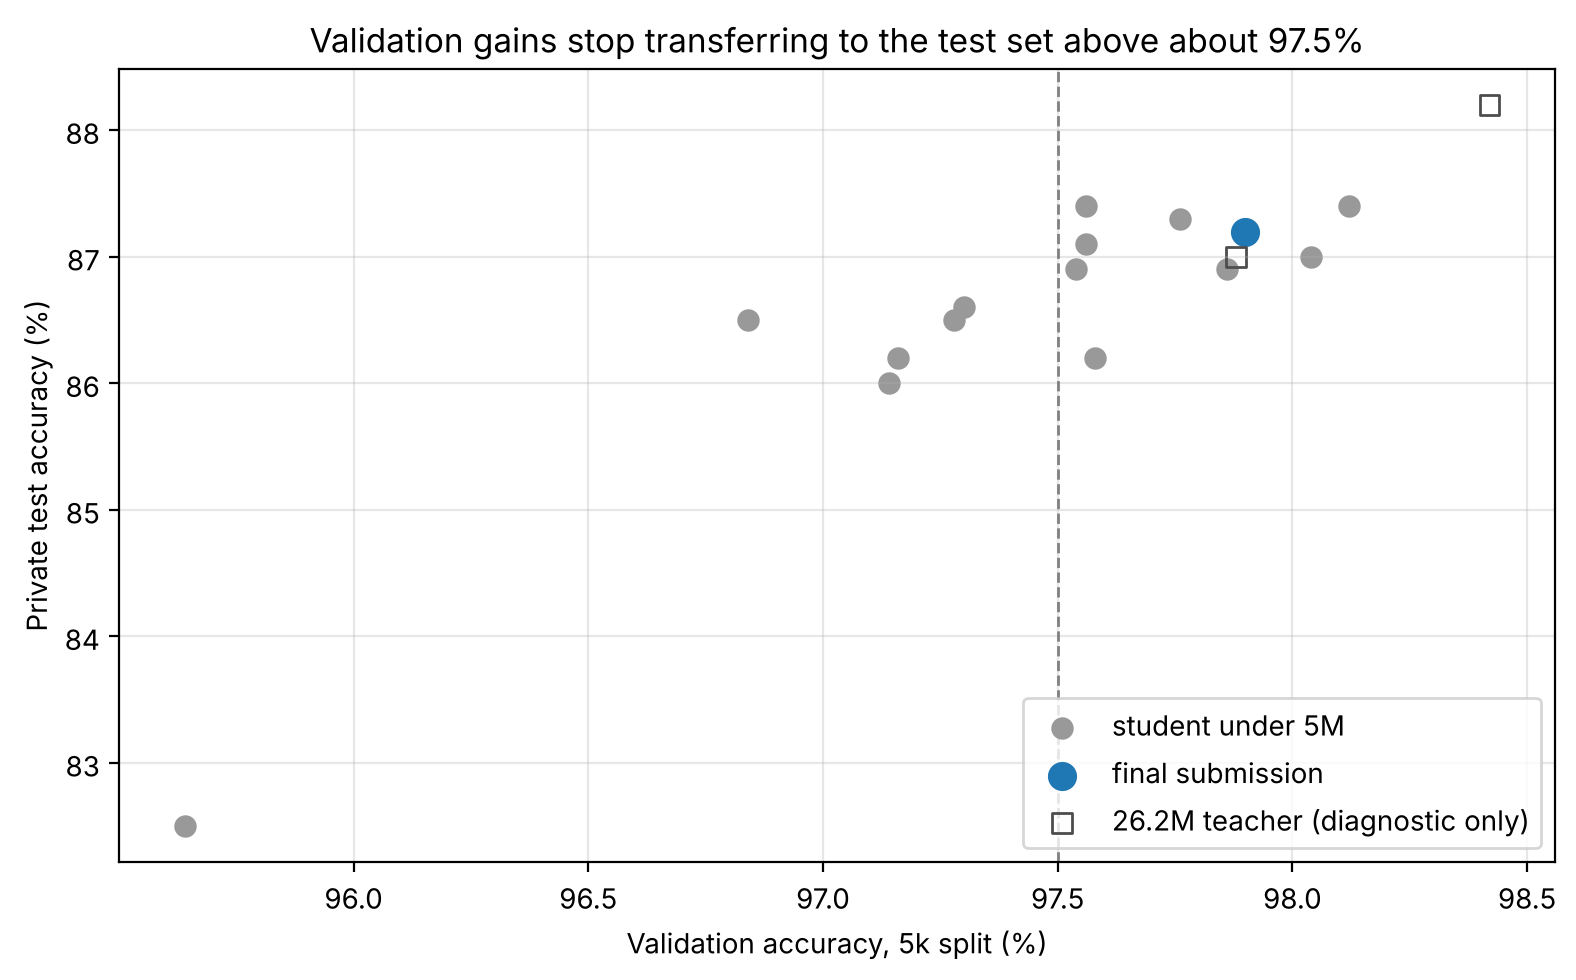

In [5]:
runs = [  # name, validation, public, private, kind
    ('Plain WRN-22 (crop+flip)', 0.9564, 0.854, 0.825, 'student'),
    ('Baseline (TA, erasing, mix, EMA)', 0.9714, None, 0.860, 'student'),
    ('KD 1x WRN-28-10', 0.9716, 0.884, 0.862, 'student'),
    ('KD + SAM', 0.9728, 0.889, 0.865, 'student'),
    ('Direct SAM 300ep', 0.9730, 0.891, 0.866, 'student'),
    ('Direct SAM robust aug', 0.9754, 0.886, 0.869, 'student'),
    ('kd3_sam_600', 0.9758, 0.889, 0.862, 'student'),
    ('fm_600', 0.9756, 0.895, 0.871, 'student'),
    ('kd3_sam_scale_300', 0.9684, 0.886, 0.865, 'student'),
    ('kd4_sam_600', 0.9776, 0.893, 0.873, 'student'),
    ('kd5_sam_600', 0.9812, 0.895, 0.874, 'student'),
    ('kd5_lightreg_600', 0.9786, 0.898, 0.869, 'student'),
    ('kd5_ft60_control', 0.9804, 0.888, 0.870, 'student'),
    ('pyr164_kd5_600', 0.9756, 0.882, 0.874, 'student'),
    ('kd1p_sam_600 (final)', 0.9790, 0.897, 0.872, 'final'),
    ('PyramidNet-272 teacher', 0.9842, 0.901, 0.882, 'teacher'),
    ('Shake-Shake teacher', 0.9788, 0.898, 0.870, 'teacher'),
]
fig, ax = plt.subplots(figsize=(8, 5))
style = {'student': dict(c='0.6', marker='o'), 'final': dict(c='tab:blue', marker='o', s=90), 'teacher': dict(c='0.3', marker='s', facecolors='none')}
for kind, label in [('student', 'student under 5M'), ('final', 'final submission'), ('teacher', '26.2M teacher (diagnostic only)')]:
    pts = [r for r in runs if r[4] == kind]
    st = dict(style[kind]); s = st.pop('s', 50)
    if kind == 'teacher':
        ax.scatter([r[1]*100 for r in pts], [r[3]*100 for r in pts], s=s, marker='s', facecolors='none', edgecolors='0.3', label=label)
    else:
        ax.scatter([r[1]*100 for r in pts], [r[3]*100 for r in pts], s=s, label=label, **st)
ax.axvline(97.5, ls='--', c='0.5', lw=1)
ax.set_xlabel('Validation accuracy, 5k split (%)'); ax.set_ylabel('Private test accuracy (%)')
ax.set_title('Validation gains stop transferring to the test set above about 97.5%')
ax.legend(loc='lower right'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

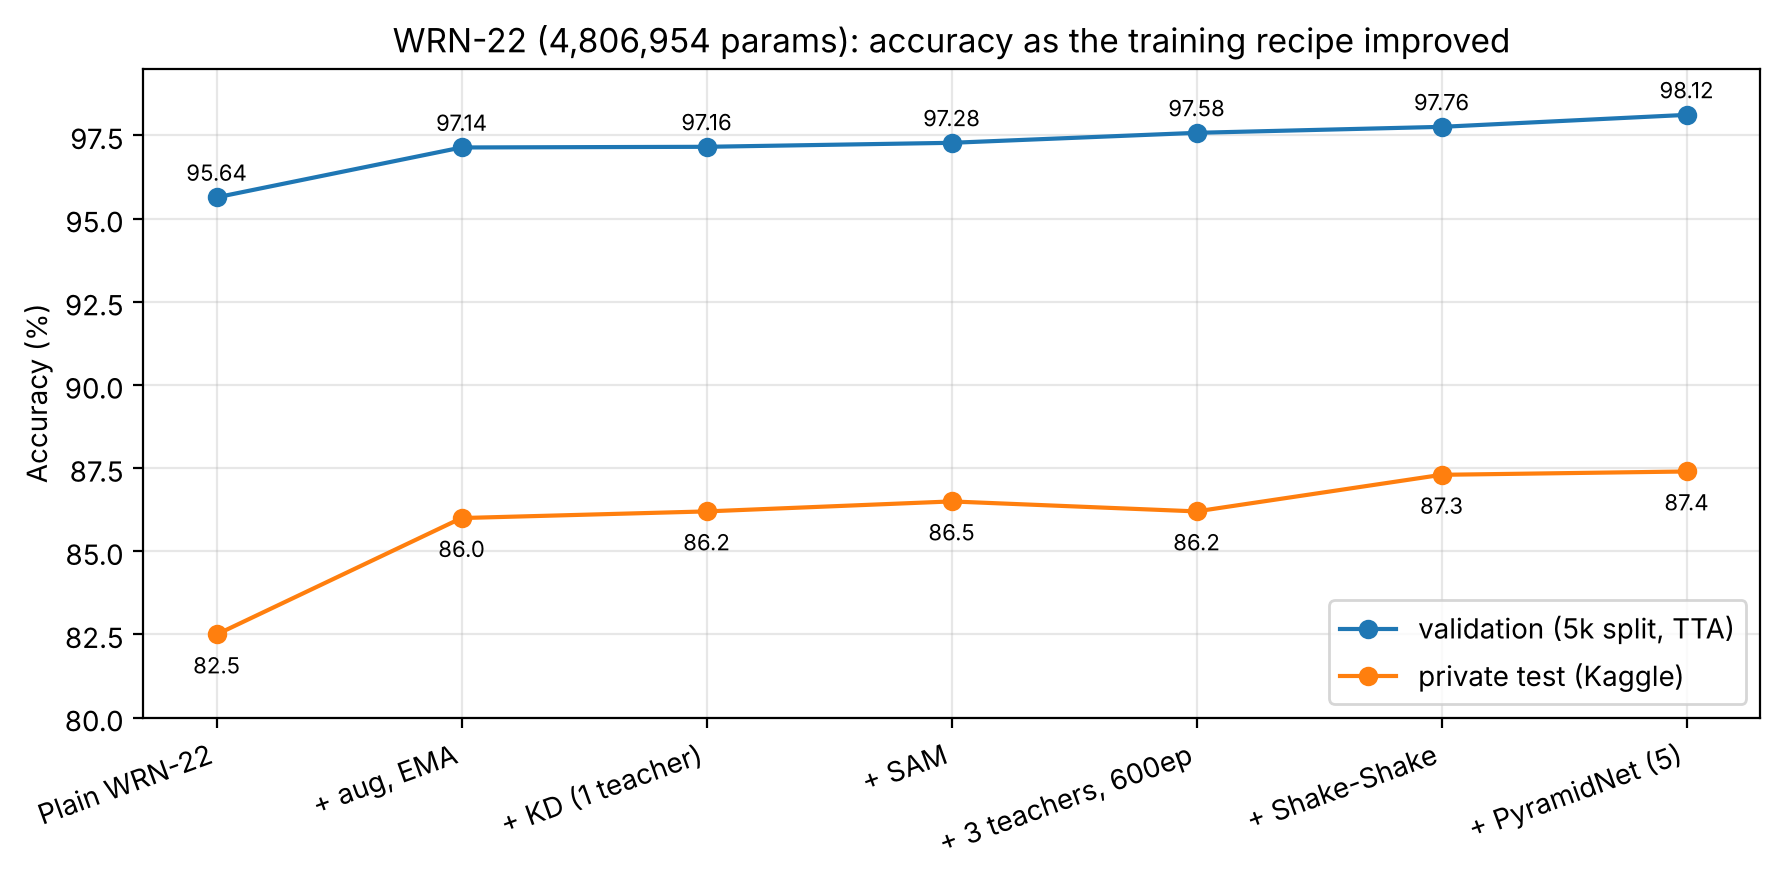

In [6]:
steps = ['Plain WRN-22', '+ aug, EMA', '+ KD (1 teacher)', '+ SAM', '+ 3 teachers, 600ep', '+ Shake-Shake', '+ PyramidNet (5)']
val  = [95.64, 97.14, 97.16, 97.28, 97.58, 97.76, 98.12]
priv = [82.5, 86.0, 86.2, 86.5, 86.2, 87.3, 87.4]
fig, ax = plt.subplots(figsize=(9, 4.5))
x = range(len(steps))
ax.plot(x, val, marker='o', label='validation (5k split, TTA)')
ax.plot(x, priv, marker='o', label='private test (Kaggle)')
for i, (v, p) in enumerate(zip(val, priv)):
    ax.annotate(f'{v:.2f}', (i, v), textcoords='offset points', xytext=(0, 6), ha='center', fontsize=8)
    ax.annotate(f'{p:.1f}', (i, p), textcoords='offset points', xytext=(0, -14), ha='center', fontsize=8)
ax.set_xticks(list(x)); ax.set_xticklabels(steps, rotation=20, ha='right')
ax.set_ylim(80, 99.5); ax.set_ylabel('Accuracy (%)'); ax.set_title('WRN-22 (4,806,954 params): accuracy as the training recipe improved')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()